STUDENT DROPOUT PREDICTION USING MACHINE LEARNING

Dataset created successfully!

Dataset Shape:
(1000, 13)

First 5 Records:


,Age,Gender,Attendance,GPA,Backlogs,Internal_Marks,Assignment_Marks,Study_Hours,Family_Income,Scholarship_Status,Parent_Education,Distance_From_College,Dropout
0,23,Female,45,8.57,0,67,69,5,15544,Yes,Graduate,46.2,No
1,20,Male,56,4.21,4,89,74,2,23275,No,School,6.1,Yes
2,24,Male,98,8.47,0,100,78,4,73248,Yes,School,7.3,No
3,21,Male,64,5.21,3,77,49,8,44550,Yes,School,28.3,Yes
4,23,Male,96,9.75,5,47,46,6,63693,Yes,Graduate,44.8,Yes



Dataset saved as:
student_dropout_dataset.csv

DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    1000 non-null   int64  
 1   Gender                 1000 non-null   object 
 2   Attendance             1000 non-null   int64  
 3   GPA                    1000 non-null   float64
 4   Backlogs               1000 non-null   int64  
 5   Internal_Marks         1000 non-null   int64  
 6   Assignment_Marks       1000 non-null   int64  
 7   Study_Hours            1000 non-null   int64  
 8   Family_Income          1000 non-null   int64  
 9   Scholarship_Status     1000 non-null   object 
 10  Parent_Education       1000 non-null   object 
 11  Distance_From_College  1000 non-null   float64
 12  Dropout                1000 non-null   object 
dtypes: float64(2), int64(7), object(4)
memory us

,Age,Attendance,GPA,Backlogs,Internal_Marks,Assignment_Marks,Study_Hours,Family_Income,Distance_From_College
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.898000,68.936000,6.985260,2.505000,65.209000,65.379000,4.405000,54241.441000,25.759400
std,2.603916,17.462269,1.735413,1.725385,20.148729,20.678902,2.266741,26549.779509,14.387064
min,17.000000,40.000000,4.000000,0.000000,30.000000,30.000000,1.000000,10028.000000,1.100000
25%,19.000000,54.000000,5.560000,1.000000,48.000000,47.000000,2.000000,30620.750000,13.700000
50%,21.000000,69.000000,6.965000,2.000000,65.000000,66.000000,4.000000,54137.500000,25.500000
75%,23.000000,84.000000,8.522500,4.000000,83.000000,84.000000,6.000000,77873.750000,38.400000
max,25.000000,100.000000,9.990000,5.000000,100.000000,100.000000,8.000000,99922.000000,50.000000


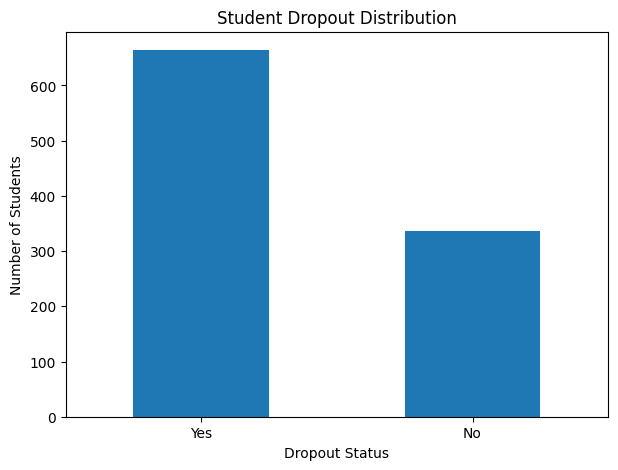

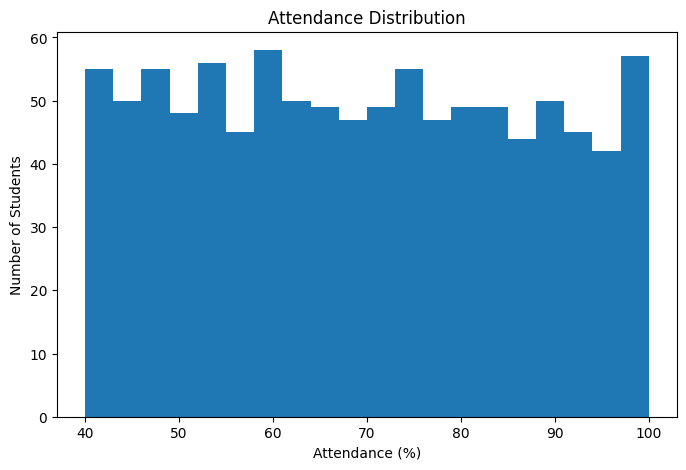

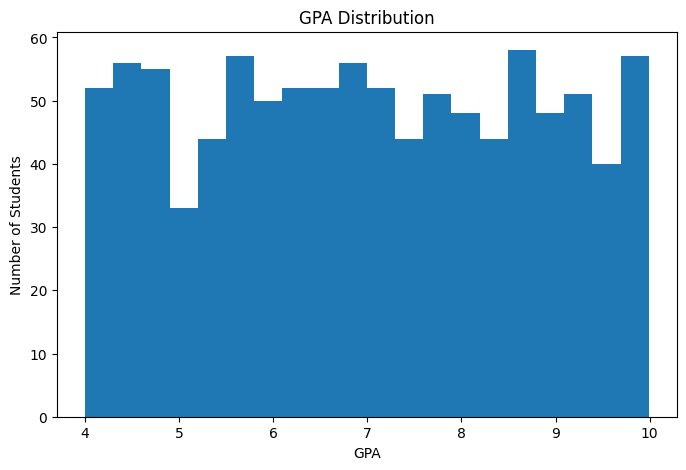

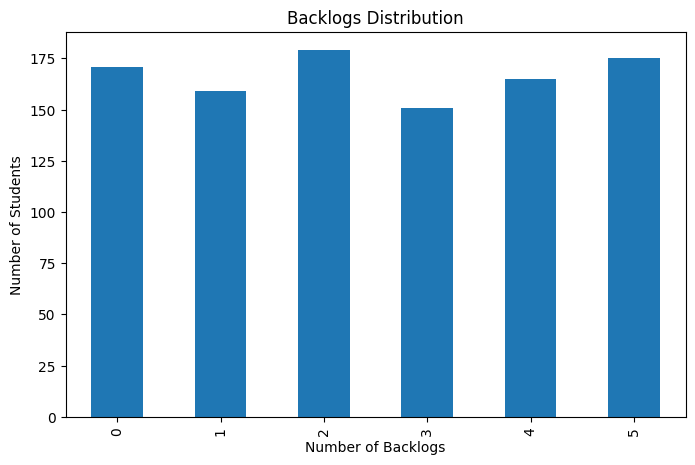

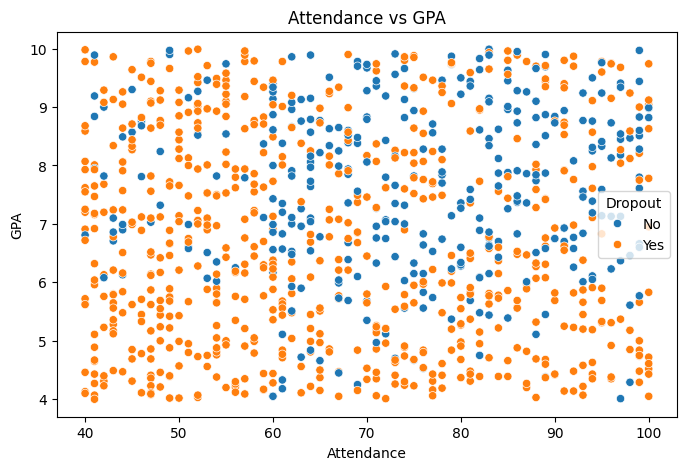


Encoded Dataset:


,Age,Gender,Attendance,GPA,Backlogs,Internal_Marks,Assignment_Marks,Study_Hours,Family_Income,Scholarship_Status,Parent_Education,Distance_From_College,Dropout
0,23,0,45,8.57,0,67,69,5,15544,1,0,46.2,0
1,20,1,56,4.21,4,89,74,2,23275,0,3,6.1,1
2,24,1,98,8.47,0,100,78,4,73248,1,3,7.3,0
3,21,1,64,5.21,3,77,49,8,44550,1,3,28.3,1
4,23,1,96,9.75,5,47,46,6,63693,1,0,44.8,1



Features:
['Age', 'Gender', 'Attendance', 'GPA', 'Backlogs', 'Internal_Marks', 'Assignment_Marks', 'Study_Hours', 'Family_Income', 'Scholarship_Status', 'Parent_Education', 'Distance_From_College']

Target:
Dropout

Training Data:
(800, 12)

Testing Data:
(200, 12)

MODEL ACCURACY COMPARISON


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.80,80.0
1,Decision Tree,0.95,95.0
2,Random Forest,0.98,98.0


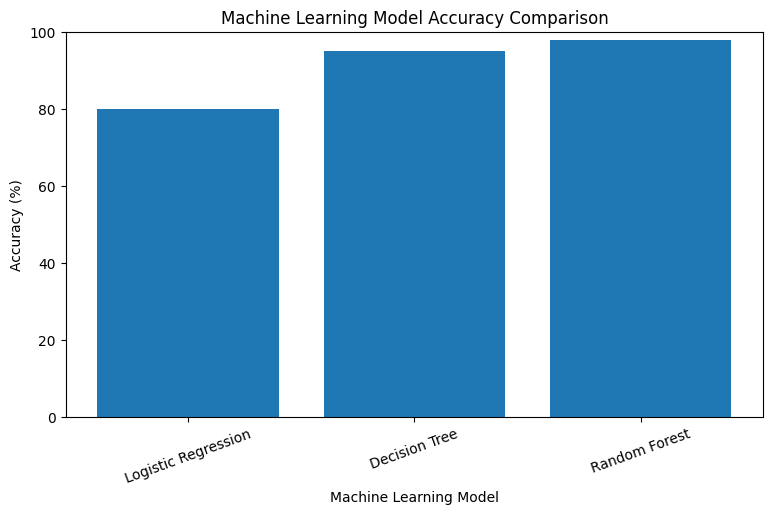


Best Model: Random Forest
Best Model Accuracy: 98.0 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      0.96      0.97        67
           1       0.98      0.99      0.99       133

    accuracy                           0.98       200
   macro avg       0.98      0.97      0.98       200
weighted avg       0.98      0.98      0.98       200



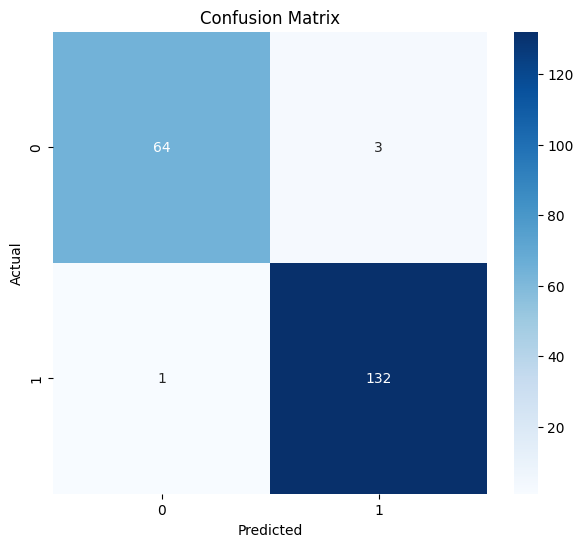


Feature Importance:


,Importance
Backlogs,0.166569
Internal_Marks,0.148121
GPA,0.147510
Attendance,0.143843
Assignment_Marks,0.125588
Study_Hours,0.110991
Distance_From_College,0.049416
Family_Income,0.048528
Age,0.029670
Parent_Education,0.015845


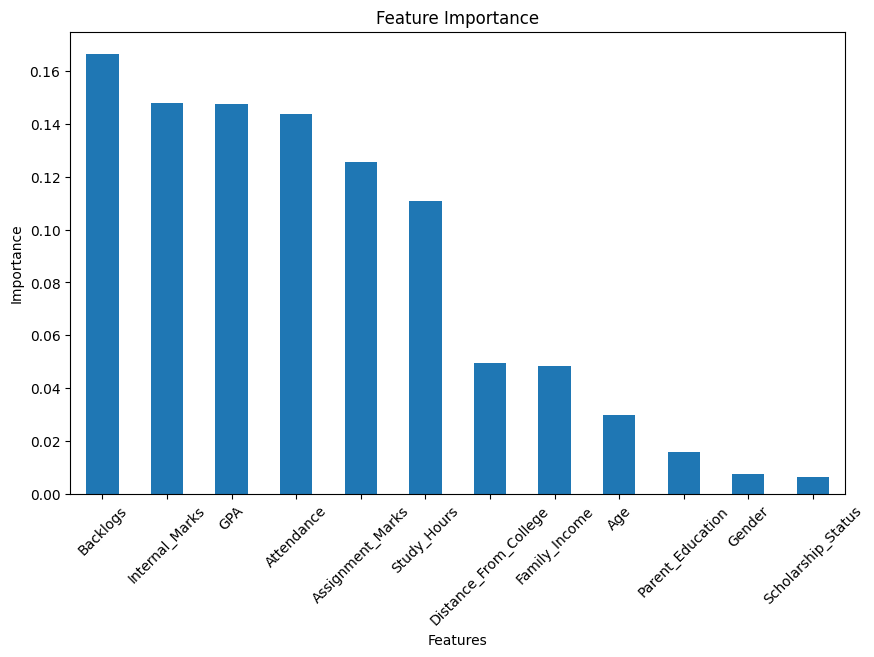


STUDENT DROPOUT PREDICTION
Prediction: Yes
Dropout Probability: 99.0 %

⚠️ ALERT: Student may be at risk of dropping out.

FILES SAVED
student_dropout_dataset.csv
student_dropout_model.pkl
student_dropout_scaler.pkl
student_dropout_label_encoders.pkl

You can download the files from Colab.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ============================================================
# STUDENT DROPOUT PREDICTION USING MACHINE LEARNING
# Complete Google Colab Project
# ============================================================

# =========================
# 1. IMPORT LIBRARIES
# =========================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("=" * 60)
print("STUDENT DROPOUT PREDICTION USING MACHINE LEARNING")
print("=" * 60)


# =========================
# 2. CREATE DATASET
# =========================

np.random.seed(42)

n = 1000

age = np.random.randint(17, 26, n)

gender = np.random.choice(
    ["Male", "Female"],
    n
)

attendance = np.random.randint(
    40, 101, n
)

gpa = np.round(
    np.random.uniform(4.0, 10.0, n),
    2
)

backlogs = np.random.randint(
    0, 6, n
)

internal_marks = np.random.randint(
    30, 101, n
)

assignment_marks = np.random.randint(
    30, 101, n
)

study_hours = np.random.randint(
    1, 9, n
)

family_income = np.random.randint(
    10000, 100001, n
)

scholarship = np.random.choice(
    ["Yes", "No"],
    n
)

parent_education = np.random.choice(
    [
        "School",
        "Intermediate",
        "Graduate",
        "Postgraduate"
    ],
    n
)

distance = np.round(
    np.random.uniform(1, 50, n),
    1
)


# =========================
# 3. CREATE DROPOUT TARGET
# =========================

dropout_score = (

    (attendance < 60).astype(int)

    + (gpa < 6).astype(int)

    + (backlogs >= 3).astype(int)

    + (internal_marks < 50).astype(int)

    + (assignment_marks < 50).astype(int)

    + (study_hours <= 2).astype(int)

)

dropout = np.where(
    dropout_score >= 2,
    "Yes",
    "No"
)


# =========================
# 4. CREATE DATAFRAME
# =========================

df = pd.DataFrame({

    "Age": age,

    "Gender": gender,

    "Attendance": attendance,

    "GPA": gpa,

    "Backlogs": backlogs,

    "Internal_Marks": internal_marks,

    "Assignment_Marks": assignment_marks,

    "Study_Hours": study_hours,

    "Family_Income": family_income,

    "Scholarship_Status": scholarship,

    "Parent_Education": parent_education,

    "Distance_From_College": distance,

    "Dropout": dropout

})


print("\nDataset created successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())


# =========================
# 5. SAVE DATASET
# =========================

df.to_csv(
    "student_dropout_dataset.csv",
    index=False
)

print("\nDataset saved as:")
print("student_dropout_dataset.csv")


# =========================
# 6. DATA INFORMATION
# =========================

print("\n" + "=" * 60)
print("DATA INFORMATION")
print("=" * 60)

print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# =========================
# 7. STATISTICAL SUMMARY
# =========================

print("\nStatistical Summary:")
display(df.describe())


# =========================
# 8. DROPOUT DISTRIBUTION
# =========================

plt.figure(figsize=(7, 5))

df["Dropout"].value_counts().plot(
    kind="bar"
)

plt.title(
    "Student Dropout Distribution"
)

plt.xlabel(
    "Dropout Status"
)

plt.ylabel(
    "Number of Students"
)

plt.xticks(rotation=0)

plt.show()


# =========================
# 9. ATTENDANCE DISTRIBUTION
# =========================

plt.figure(figsize=(8, 5))

plt.hist(
    df["Attendance"],
    bins=20
)

plt.title(
    "Attendance Distribution"
)

plt.xlabel(
    "Attendance (%)"
)

plt.ylabel(
    "Number of Students"
)

plt.show()


# =========================
# 10. GPA DISTRIBUTION
# =========================

plt.figure(figsize=(8, 5))

plt.hist(
    df["GPA"],
    bins=20
)

plt.title(
    "GPA Distribution"
)

plt.xlabel(
    "GPA"
)

plt.ylabel(
    "Number of Students"
)

plt.show()


# =========================
# 11. BACKLOG DISTRIBUTION
# =========================

plt.figure(figsize=(8, 5))

df["Backlogs"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title(
    "Backlogs Distribution"
)

plt.xlabel(
    "Number of Backlogs"
)

plt.ylabel(
    "Number of Students"
)

plt.show()


# =========================
# 12. ATTENDANCE VS GPA
# =========================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="GPA",
    hue="Dropout"
)

plt.title(
    "Attendance vs GPA"
)

plt.show()


# =========================
# 13. ENCODING
# =========================

df_ml = df.copy()

label_encoders = {}

categorical_columns = [

    "Gender",

    "Scholarship_Status",

    "Parent_Education",

    "Dropout"

]

for column in categorical_columns:

    encoder = LabelEncoder()

    df_ml[column] = encoder.fit_transform(
        df_ml[column]
    )

    label_encoders[column] = encoder


print("\nEncoded Dataset:")
display(df_ml.head())


# =========================
# 14. FEATURES AND TARGET
# =========================

X = df_ml.drop(
    "Dropout",
    axis=1
)

y = df_ml["Dropout"]


print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print("Dropout")


# =========================
# 15. TRAIN TEST SPLIT
# =========================

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)


print("\nTraining Data:")
print(X_train.shape)

print("\nTesting Data:")
print(X_test.shape)


# =========================
# 16. FEATURE SCALING
# =========================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)


# =========================
# 17. MODEL 1
# LOGISTIC REGRESSION
# =========================

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_prediction = logistic_model.predict(
    X_test_scaled
)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_prediction
)


# =========================
# 18. MODEL 2
# DECISION TREE
# =========================

decision_tree_model = DecisionTreeClassifier(

    random_state=42,

    max_depth=6

)

decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_prediction = decision_tree_model.predict(
    X_test
)

decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_prediction
)


# =========================
# 19. MODEL 3
# RANDOM FOREST
# =========================

random_forest_model = RandomForestClassifier(

    n_estimators=100,

    random_state=42

)

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_prediction = random_forest_model.predict(
    X_test
)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_prediction
)


# =========================
# 20. MODEL COMPARISON
# =========================

results = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Decision Tree",

        "Random Forest"

    ],

    "Accuracy": [

        logistic_accuracy,

        decision_tree_accuracy,

        random_forest_accuracy

    ]

})


results["Accuracy (%)"] = (
    results["Accuracy"] * 100
).round(2)


print("\n" + "=" * 60)
print("MODEL ACCURACY COMPARISON")
print("=" * 60)

display(results)


# =========================
# 21. ACCURACY GRAPH
# =========================

plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Accuracy (%)"]
)

plt.title(
    "Machine Learning Model Accuracy Comparison"
)

plt.xlabel(
    "Machine Learning Model"
)

plt.ylabel(
    "Accuracy (%)"
)

plt.xticks(
    rotation=20
)

plt.ylim(
    0,
    100
)

plt.show()


# =========================
# 22. SELECT BEST MODEL
# =========================

best_index = results["Accuracy"].idxmax()

best_model_name = results.loc[
    best_index,
    "Model"
]

print(
    "\nBest Model:",
    best_model_name
)


if best_model_name == "Logistic Regression":

    best_model = logistic_model

    X_test_best = X_test_scaled

    best_prediction = logistic_prediction


elif best_model_name == "Decision Tree":

    best_model = decision_tree_model

    X_test_best = X_test

    best_prediction = decision_tree_prediction


else:

    best_model = random_forest_model

    X_test_best = X_test

    best_prediction = random_forest_prediction


best_accuracy = accuracy_score(
    y_test,
    best_prediction
)


print(
    "Best Model Accuracy:",
    round(
        best_accuracy * 100,
        2
    ),
    "%"
)


# =========================
# 23. CLASSIFICATION REPORT
# =========================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        best_prediction
    )
)


# =========================
# 24. CONFUSION MATRIX
# =========================

cm = confusion_matrix(
    y_test,
    best_prediction
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()


# =========================
# 25. FEATURE IMPORTANCE
# =========================

if best_model_name in [
    "Decision Tree",
    "Random Forest"
]:

    importance = pd.Series(

        best_model.feature_importances_,

        index=X.columns

    ).sort_values(
        ascending=False
    )

    print("\nFeature Importance:")

    display(
        importance.to_frame(
            "Importance"
        )
    )

    plt.figure(figsize=(10, 6))

    importance.plot(
        kind="bar"
    )

    plt.title(
        "Feature Importance"
    )

    plt.xlabel(
        "Features"
    )

    plt.ylabel(
        "Importance"
    )

    plt.xticks(
        rotation=45
    )

    plt.show()


# =========================
# 26. CREATE NEW STUDENT
# =========================

new_student = pd.DataFrame({

    "Age": [20],

    "Gender": [
        label_encoders[
            "Gender"
        ].transform(
            ["Female"]
        )[0]
    ],

    "Attendance": [55],

    "GPA": [5.5],

    "Backlogs": [3],

    "Internal_Marks": [45],

    "Assignment_Marks": [50],

    "Study_Hours": [2],

    "Family_Income": [30000],

    "Scholarship_Status": [
        label_encoders[
            "Scholarship_Status"
        ].transform(
            ["No"]
        )[0]
    ],

    "Parent_Education": [
        label_encoders[
            "Parent_Education"
        ].transform(
            ["School"]
        )[0]
    ],

    "Distance_From_College": [20]

})


# =========================
# 27. PREPARE NEW STUDENT
# =========================

if best_model_name == "Logistic Regression":

    new_student_scaled = scaler.transform(
        new_student
    )

    prediction = best_model.predict(
        new_student_scaled
    )

    probability = best_model.predict_proba(
        new_student_scaled
    )

else:

    prediction = best_model.predict(
        new_student
    )

    probability = best_model.predict_proba(
        new_student
    )


# =========================
# 28. CONVERT PREDICTION
# =========================

prediction_label = label_encoders[
    "Dropout"
].inverse_transform(
    prediction
)


print("\n" + "=" * 60)
print("STUDENT DROPOUT PREDICTION")
print("=" * 60)

print(
    "Prediction:",
    prediction_label[0]
)


# =========================
# 29. DROPOUT PROBABILITY
# =========================

dropout_encoded = label_encoders[
    "Dropout"
].transform(
    ["Yes"]
)[0]


class_position = list(
    best_model.classes_
).index(
    dropout_encoded
)

dropout_probability = probability[
    0,
    class_position
]


print(
    "Dropout Probability:",
    round(
        dropout_probability * 100,
        2
    ),
    "%"
)


# =========================
# 30. FINAL RESULT
# =========================

if prediction_label[0] == "Yes":

    print(
        "\n⚠️ ALERT:"
        " Student may be at risk of dropping out."
    )

else:

    print(
        "\n✅ RESULT:"
        " Student is predicted to continue studies."
    )


# =========================
# 31. SAVE BEST MODEL
# =========================

joblib.dump(
    best_model,
    "student_dropout_model.pkl"
)

joblib.dump(
    scaler,
    "student_dropout_scaler.pkl"
)

joblib.dump(
    label_encoders,
    "student_dropout_label_encoders.pkl"
)


print("\n" + "=" * 60)
print("FILES SAVED")
print("=" * 60)

print(
    "student_dropout_dataset.csv"
)

print(
    "student_dropout_model.pkl"
)

print(
    "student_dropout_scaler.pkl"
)

print(
    "student_dropout_label_encoders.pkl"
)


# =========================
# 32. DOWNLOAD FILES
# =========================

from google.colab import files

print("\nYou can download the files from Colab.")

files.download(
    "student_dropout_dataset.csv"
)